# Notebook 02: PMIC trims and customer OTP configuration

**Chip:** PMIC (power-management IC): one reference voltage feeding 4 output rails (buck1, buck2, ldo1, ldo2), plus protection thresholds and a current sensor.

**Datasets:**
- `pmic_trim_otp.csv`: 11,060 dies, 3 derivatives (PMIC-P1 base; P2 and C7 small)
- `pmic_otp_config_requests.csv`: 400 customer configuration requests

**What this notebook does (6 tasks):**

| Task | Question | Method |
|---|---|---|
| **A (main)** | Predict all 4 rail trim codes **from the reference measurement only**, without measuring the rails | ML regression, single- vs. multi-output |
| B | Predict the reference and threshold trims (OVP, UVLO, current limit) | formula vs. ML |
| C | Calibrate the current sensor from a 2-point measurement instead of a full sweep | formula vs. ML |
| D | Screen for latent defects (anomaly detection) | rule vs. Isolation Forest |
| E | Transfer to derivatives P2 and C7 with no retraining | evaluation |
| F | Check customer OTP requests | rule checker vs. ML classifier |

It ends with optimization (feature engineering and tuning), final model selection, test-time savings, and why the chosen models fit.

**Colab:** Runtime → Run all, and upload the dataset zip or the two CSVs when asked.

## 0.1 Setup

In [1]:
import importlib, subprocess, sys
for pkg in ["xgboost", "lightgbm"]:
    if importlib.util.find_spec(pkg) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg])

import os, glob, zipfile, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (GroupShuffleSplit, GroupKFold, RandomizedSearchCV,
                                     StratifiedKFold, cross_val_predict)
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import (mean_absolute_error, r2_score, accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score, average_precision_score)
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED)
print("Libraries loaded")

Libraries loaded


## 0.2 Load the two datasets
Searches the folder (and subfolders) for the raw CSVs; in Colab, asks for an upload if they are missing (a zip is extracted automatically).

In [2]:
NEEDED = ["pmic_trim_otp.csv", "pmic_otp_config_requests.csv"]

def find(name):
    hits = [h for h in glob.glob(f"**/{name}", recursive=True) if "cleaned" not in h]
    return min(hits, key=len) if hits else None

if any(find(f) is None for f in NEEDED):
    try:
        from google.colab import files
        print("Upload the dataset zip or:", NEEDED)
        for fname in files.upload():
            if fname.lower().endswith(".zip"):
                zipfile.ZipFile(fname).extractall("dataset_upload")
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook")

pmic_raw = pd.read_csv(find("pmic_trim_otp.csv"))
req_raw = pd.read_csv(find("pmic_otp_config_requests.csv"))
print("pmic_trim_otp           :", pmic_raw.shape)
print("pmic_otp_config_requests:", req_raw.shape)

pmic_trim_otp           : (11060, 63)
pmic_otp_config_requests: (400, 10)


## 0.3 Apply the cleaning from notebook 00
The same conversions as notebook 00, repeated here so this notebook runs on its own:
- I²C address hex → number
- power-up sequence → position of each rail
- OTP requests → rule flags

In [3]:
RAILS = ["buck1", "buck2", "ldo1", "ldo2"]
LIMITS = {"buck1": (0.4, 1.8), "buck2": (0.4, 1.8), "ldo1": (0.8, 3.3), "ldo2": (1.2, 3.6)}

pmic = pmic_raw.copy()
pmic["i2c_addr_int"] = pmic.i2c_addr.apply(lambda h: int(h, 16))
for r in RAILS:
    pmic[f"seq_pos_{r}"] = pmic.sequence.apply(lambda s: s.split(">").index(r) + 1)

req = req_raw.copy()
req["i2c_addr_int"] = req.i2c_addr.apply(lambda h: int(h, 16))
req["bus_list"] = req.other_addresses_on_bus.fillna("").apply(lambda s: [int(a, 16) for a in s.split(";") if a])
req["n_bus_devices"] = req.bus_list.apply(len)
steps = req.sequence.str.split(">")
for r in RAILS:
    req[f"seq_pos_{r}"] = steps.apply(lambda s: s.index(r) + 1 if r in s else 0)
print("Missing values:", int(pmic.isna().sum().sum()), "/", int(req.isna().sum().sum()), "| cleaning applied")

Missing values: 0 / 0 | cleaning applied


# Part 1: Focused EDA for the modelling questions
Notebook 00 already did the general EDA. Here we look only at what drives the models.

## 1.1 Derivatives: same die, different defaults
Each derivative has different default rail voltages, sequence and I²C address. The trim **method** is the same, which is why one model can serve all of them.

In [4]:
cols = ["package"] + [f"{r}_target_V" for r in RAILS] + ["sequence", "i2c_addr"]
info = pmic.groupby("derivative")[cols].first()
info.insert(0, "dies", pmic.derivative.value_counts())
info.insert(1, "wafers", pmic.groupby("derivative").wafer_id.nunique())
info

,dies,wafers,package,buck1_target_V,buck2_target_V,ldo1_target_V,ldo2_target_V,sequence,i2c_addr
derivative,,,,,,,,,
PMIC-C7,1106,2,QFN24,0.90,1.05,2.5,3.3,buck1>ldo1>buck2>ldo2,0x62
PMIC-P1,8295,15,WLCSP,0.80,1.10,1.8,3.3,buck1>buck2>ldo1>ldo2,0x60
PMIC-P2,1659,3,QFN24,0.75,1.20,1.8,3.3,buck2>buck1>ldo1>ldo2,0x61


## 1.2 The coupling: every rail follows the trimmed reference
Each rail's untrimmed output (as a ratio of its target) is plotted against the trimmed reference. A clear trend means the rails can be predicted **from the reference alone**, which is task A.

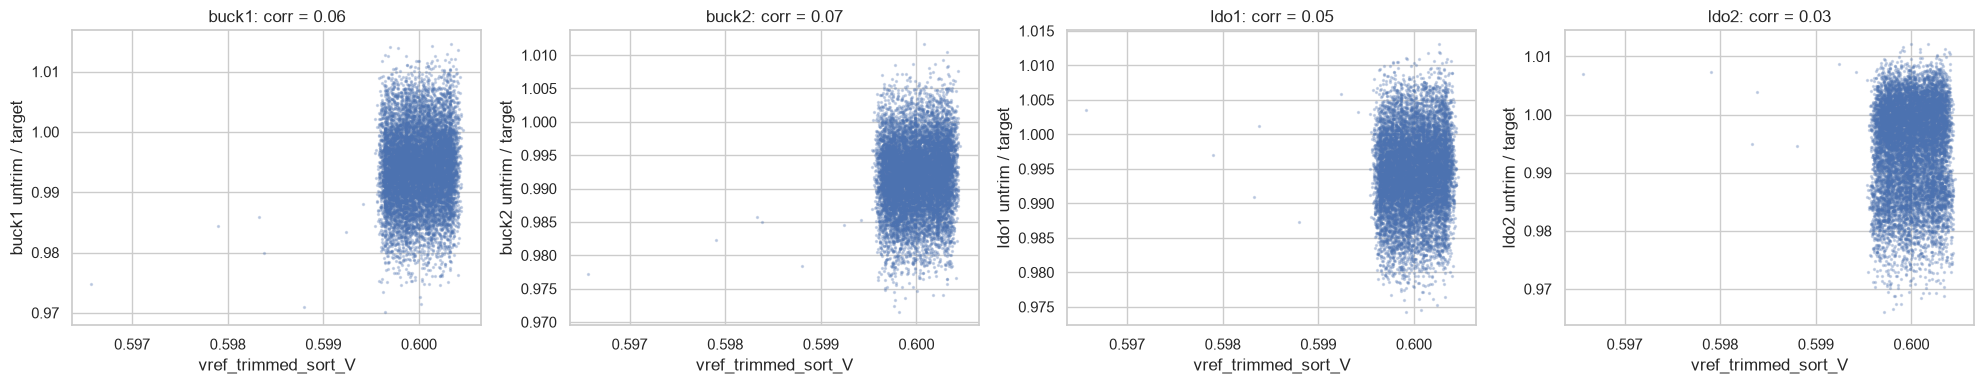

In [5]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
for a, r in zip(ax, RAILS):
    ratio = pmic[f"{r}_untrim_V"] / pmic[f"{r}_target_V"]
    a.scatter(pmic.vref_trimmed_sort_V, ratio, s=2, alpha=0.25)
    a.set(xlabel="vref_trimmed_sort_V", ylabel=f"{r} untrim / target",
          title=f"{r}: corr = {pmic.vref_trimmed_sort_V.corr(ratio):.2f}")
plt.tight_layout(); plt.show()

## 1.3 Rail trim codes vs. process monitors
The rails also respond to process variation (PCM), each in a different way. That leftover part is what the ML model learns.

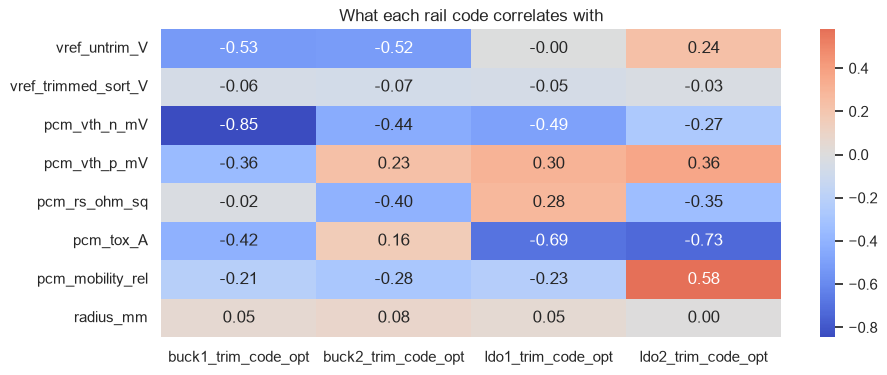

In [6]:
PCM = ["pcm_vth_n_mV", "pcm_vth_p_mV", "pcm_rs_ohm_sq", "pcm_tox_A", "pcm_mobility_rel"]
POS = ["x_mm", "y_mm", "radius_mm"]
rail_codes = [f"{r}_trim_code_opt" for r in RAILS]
plt.figure(figsize=(10, 4))
sns.heatmap(pmic[["vref_untrim_V", "vref_trimmed_sort_V"] + PCM + ["radius_mm"] + rail_codes].corr().loc[
    ["vref_untrim_V", "vref_trimmed_sort_V"] + PCM + ["radius_mm"], rail_codes], annot=True, fmt=".2f",
    cmap="coolwarm", center=0)
plt.title("What each rail code correlates with"); plt.show()

## 1.4 What trimming costs today
A full binary search for every trim: reference (6 bits), 4 rails (6 bits each), OVP and UVLO (4 bits), current limit (5 bits), plus retries. Each iteration takes 0.8 ms.

In [7]:
print(pmic[["conv_trim_iterations", "conv_trim_time_ms"]].describe().loc[["mean", "min", "max"]].round(2).to_string())
MS_PER_ITER = (pmic.conv_trim_time_ms / pmic.conv_trim_iterations).median()
CONV_ITERS = pmic.conv_trim_iterations.mean()
print(f"\nms per iteration: {MS_PER_ITER:.2f} | average iterations per die today: {CONV_ITERS:.1f}")

      conv_trim_iterations  conv_trim_time_ms
mean                 44.66              35.73
min                  43.00              34.40
max                  48.00              38.40

ms per iteration: 0.80 | average iterations per die today: 44.7


# Part 2: Split by wafer
Train on **PMIC-P1** wafers and test on held-out P1 wafers. Whole wafers go to one side only, because dies on one wafer are correlated. P2 and C7 are kept apart for the transfer test (task E).

In [8]:
base = pmic[pmic.derivative == "PMIC-P1"].reset_index(drop=True)
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=SEED).split(base, groups=base.wafer_id))
train, test = base.iloc[tr_idx].reset_index(drop=True), base.iloc[te_idx].reset_index(drop=True)
others = pmic[pmic.derivative != "PMIC-P1"].reset_index(drop=True)
print(f"Train: {len(train)} dies, {train.wafer_id.nunique()} wafers | Test: {len(test)} dies, {test.wafer_id.nunique()} wafers")
print("Shared wafers:", len(set(train.wafer_id) & set(test.wafer_id)), "| Transfer set:", others.derivative.value_counts().to_dict())

Train: 6083 dies, 11 wafers | Test: 2212 dies, 4 wafers
Shared wafers: 0 | Transfer set: {'PMIC-P2': 1659, 'PMIC-C7': 1106}


# Part 3: Shared tools

## 3.1 Trim settings and the evaluation function
`CFG` holds each trim's physics: bits, "no change" code, step per code, whether the step is a percentage (`mult`), and the sort spec.
The evaluation uses the same test-floor metrics as notebook 01:

| Metric | Meaning |
|---|---|
| Exact % / ±1 code % | Predicted code is exact, or within one step (fixed with one extra measurement) |
| AI iterations | Predict → verify: 1 if exact, 2 if off by one, otherwise fall back to the full search (1 + bits) |
| Iterations saved % | Compared with today's binary search |
| Spec pass % | Value with the predicted code is still inside the sort spec (approximation with the ideal step) |

In [9]:
CFG = {"vref": dict(label="vref_trim_code_opt", untrim="vref_untrim_V", bits=6, mid=32, lsb=0.00075, mult=False,
                    target=0.600, trimmed="vref_trimmed_sort_V", spec=0.0025, conv=6.33),
       "ovp":  dict(label="ovp_trim_code_opt", untrim="ovp_untrim_V", bits=4, mid=8, lsb=0.005, mult=True,
                    target=3.63, trimmed="ovp_trimmed_V", spec=None, conv=4),
       "uvlo": dict(label="uvlo_trim_code_opt", untrim="uvlo_untrim_V", bits=4, mid=8, lsb=0.005, mult=True,
                    target=2.70, trimmed="uvlo_trimmed_V", spec=None, conv=4),
       "ilim": dict(label="ilim_trim_code_opt", untrim="ilim_untrim_A", bits=5, mid=16, lsb=0.01, mult=True,
                    target=3.0, trimmed="ilim_trimmed_A", spec=None, conv=5)}
for r in RAILS:
    CFG[r] = dict(label=f"{r}_trim_code_opt", untrim=f"{r}_untrim_V", bits=6, mid=32, lsb=0.002, mult=True,
                  target=f"{r}_target_V", trimmed=f"{r}_trimmed_sort_V", spec=0.005, conv=6.33)


def tgt(c, data):
    return data[c["target"]].values if isinstance(c["target"], str) else c["target"]


def to_code(pred, t):
    return np.clip(np.round(pred), 0, 2 ** CFG[t]["bits"] - 1).astype(int)


def formula_code(t, data):
    c = CFG[t]; u = data[c["untrim"]].values
    return c["mid"] + (tgt(c, data) / u - 1) / c["lsb"] if c["mult"] else c["mid"] - (u - c["target"]) / c["lsb"]


def evaluate(t, data, pred_raw, name=""):
    c = CFG[t]; y = data[c["label"]].values
    code_ = to_code(pred_raw, t); err = np.abs(code_ - y)
    ai = np.where(err == 0, 1, np.where(err <= 1, 2, 1 + c["bits"]))
    out = {"model": name, "trim": t, "MAE": mean_absolute_error(y, pred_raw), "R2": r2_score(y, pred_raw),
           "exact_%": (err == 0).mean() * 100, "within1_%": (err <= 1).mean() * 100,
           "within2_%": (err <= 2).mean() * 100, "AI_iters": ai.mean(), "conv_iters": c["conv"],
           "iters_saved_%": (1 - ai.mean() / c["conv"]) * 100}
    if c["spec"]:
        s = data[c["trimmed"]].values
        val = s * (1 + (code_ - y) * c["lsb"]) if c["mult"] else s + (code_ - y) * c["lsb"]
        out["spec_pass_%"] = (np.abs(val / tgt(c, data) - 1) <= c["spec"]).mean() * 100
    return out

print("Ready:", list(CFG))

Ready: ['vref', 'ovp', 'uvlo', 'ilim', 'buck1', 'buck2', 'ldo1', 'ldo2']


## 3.2 Candidate models
The same six model families as notebook 01, so the results are comparable.

In [10]:
def make_models():
    return {
        "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
        "RandomForest": RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                                colsample_bytree=0.8, random_state=SEED, n_jobs=-1),
        "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, random_state=SEED, verbose=-1),
        "MLP": make_pipeline(StandardScaler(), MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=2000,
                                                            early_stopping=True, random_state=SEED)),
    }

def rank(frame):
    return frame.sort_values(["within1_%", "exact_%", "MAE"], ascending=[False, False, True])

fitted = {}
print(list(make_models()))

['Ridge', 'RandomForest', 'XGBoost', 'LightGBM', 'MLP']


# Part 4, Task A (main): rail trim codes

Two scenarios:
- **Scenario 1: measure every rail (today).** Each rail's untrimmed output is measured, then the code is computed. This is the reference point.
- **Scenario 2: reference only (the AI goal).** Only the reference is measured. All 4 rail codes are predicted from it plus process data, so **4 rail measurements and their search loops are skipped**.

## 4.1 Scenario 1: with rail measurements (formula vs. ML)

In [11]:
for r in RAILS:
    for d in (train, test, others):
        d[f"{r}_untrim_ratio"] = d[f"{r}_untrim_V"] / d[f"{r}_target_V"]

res_s1 = []
for r in RAILS:
    res_s1.append(evaluate(r, test, formula_code(r, test), "Formula (rail measured)"))
    f = [f"{r}_untrim_ratio", "vref_trimmed_sort_V"] + PCM + POS
    m = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(train[f], train[CFG[r]["label"]])
    res_s1.append(evaluate(r, test, m.predict(test[f]), "RandomForest (rail measured)"))
res_s1 = pd.DataFrame(res_s1)
print(res_s1[["trim", "model", "exact_%", "within1_%", "AI_iters", "spec_pass_%"]].round(2).to_string(index=False))

 trim                        model  exact_%  within1_%  AI_iters  spec_pass_%
buck1      Formula (rail measured)    79.02      100.0      1.21        100.0
buck1 RandomForest (rail measured)    85.94      100.0      1.14        100.0
buck2      Formula (rail measured)    77.67      100.0      1.22        100.0
buck2 RandomForest (rail measured)    85.90      100.0      1.14        100.0
 ldo1      Formula (rail measured)    71.02      100.0      1.29        100.0
 ldo1 RandomForest (rail measured)    86.71      100.0      1.13        100.0
 ldo2      Formula (rail measured)    67.95      100.0      1.32        100.0
 ldo2 RandomForest (rail measured)    84.00      100.0      1.16        100.0


## 4.2 Scenario 2: from the reference only, all models
Features: untrimmed and trimmed reference + 5 PCM + wafer position. **No rail measurement.**

In [12]:
REF_FEATS = ["vref_untrim_V", "vref_trimmed_sort_V"] + PCM + POS
res_s2 = []
for r in RAILS:
    for name, m in make_models().items():
        m.fit(train[REF_FEATS], train[CFG[r]["label"]])
        res_s2.append(evaluate(r, test, m.predict(test[REF_FEATS]), name)); fitted[(r, name)] = m
res_s2 = pd.DataFrame(res_s2)
for r in RAILS:
    print(f"\n===== {r} (reference only) =====")
    print(rank(res_s2[res_s2.trim == r])[["model", "MAE", "R2", "exact_%", "within1_%", "AI_iters", "spec_pass_%"]]
          .round(3).to_string(index=False))


===== buck1 (reference only) =====
       model   MAE    R2  exact_%  within1_%  AI_iters  spec_pass_%
       Ridge 0.644 0.931   46.293     93.761     1.849       99.864
     XGBoost 0.697 0.917   43.852     90.913     2.016       99.458
    LightGBM 0.719 0.912   43.354     90.145     2.059       99.231
         MLP 0.739 0.910   40.280     89.738     2.110       99.322
RandomForest 0.860 0.875   36.709     83.047     2.481       97.694

===== buck2 (reference only) =====
       model   MAE    R2  exact_%  within1_%  AI_iters  spec_pass_%
       Ridge 0.614 0.910   48.146     95.524     1.742       99.955
     XGBoost 0.682 0.888   44.394     92.812     1.915       99.503
    LightGBM 0.705 0.879   43.219     91.410     1.997       99.412
         MLP 0.726 0.872   40.868     90.461     2.068       99.367
RandomForest 0.796 0.843   38.743     86.935     2.266       98.508

===== ldo1 (reference only) =====
       model   MAE    R2  exact_%  within1_%  AI_iters  spec_pass_%
       Ri

## 4.3 One model for all 4 rails (multi-output)
The brief suggests predicting coupled trims **together**. Random Forest can output all 4 codes at once, so we compare one multi-output model against four separate models.

In [13]:
Y_cols = [CFG[r]["label"] for r in RAILS]
multi = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)
t0 = time.time(); multi.fit(train[REF_FEATS], train[Y_cols]); t_multi = time.time() - t0
P = multi.predict(test[REF_FEATS])
res_multi = pd.DataFrame([evaluate(r, test, P[:, i], "RandomForest multi-output") for i, r in enumerate(RAILS)])
cmp = pd.concat([res_s2[res_s2.model == "RandomForest"], res_multi])
print(cmp.pivot(index="trim", columns="model", values="within1_%").round(2).to_string())
print(f"\nMulti-output: 1 model, trained in {t_multi:.1f}s (vs 4 separate models)")

model  RandomForest  RandomForest multi-output
trim                                          
buck1         83.05                      80.56
buck2         86.93                      79.29
ldo1          89.01                      84.63
ldo2          84.58                      81.37

Multi-output: 1 model, trained in 3.3s (vs 4 separate models)


## 4.4 Visual comparison: scenario 1 vs. scenario 2

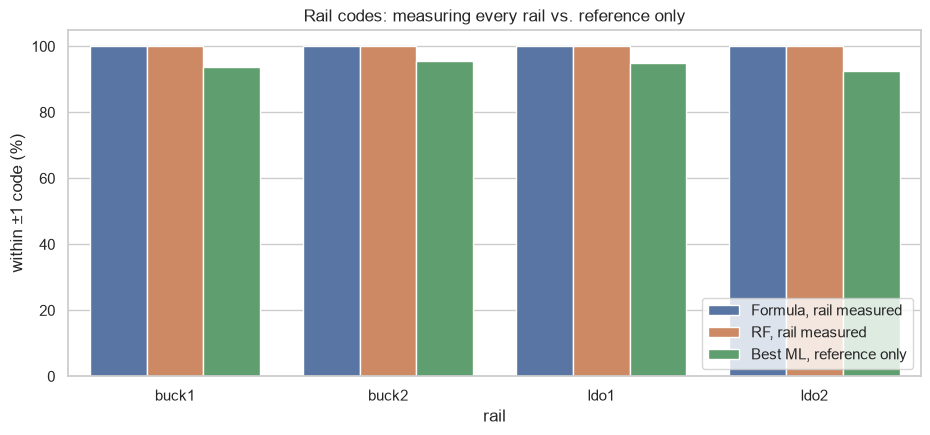

{'buck1': 'Ridge', 'buck2': 'Ridge', 'ldo1': 'Ridge', 'ldo2': 'Ridge'}


In [14]:
best_s2 = {r: rank(res_s2[res_s2.trim == r]).iloc[0] for r in RAILS}
plot = pd.concat([
    res_s1.assign(approach=res_s1.model.map(lambda m: "Formula, rail measured" if m.startswith("Formula")
                                             else "RF, rail measured")),
    pd.DataFrame([best_s2[r] for r in RAILS]).assign(approach="Best ML, reference only"),
]).rename(columns={"trim": "rail", "within1_%": "within1"})
plt.figure(figsize=(11, 4.5))
sns.barplot(data=plot, x="rail", y="within1", hue="approach")
plt.ylim(0, 105); plt.ylabel("within ±1 code (%)"); plt.title("Rail codes: measuring every rail vs. reference only")
plt.legend(loc="lower right"); plt.show()
print({r: best_s2[r].model for r in RAILS})

# Part 5, Task B: reference and threshold trims
- **vref:** predicted from its own untrimmed reading.
- **OVP / UVLO / current limit:** two options. (1) Measure each threshold and use the formula. (2) Predict it from the reference result and process data **without measuring it**.

In [15]:
res_b = []
for t in ["vref", "ovp", "uvlo", "ilim"]:
    res_b.append(evaluate(t, test, formula_code(t, test), "Formula (measured)"))
    own = [CFG[t]["untrim"]] + PCM + POS + ([] if t == "vref" else ["vref_trimmed_sort_V"])
    for label, f in [("RandomForest (measured)", own)] + ([] if t == "vref" else [("RandomForest (not measured)", REF_FEATS)]):
        m = RandomForestRegressor(n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=SEED).fit(train[f], train[CFG[t]["label"]])
        res_b.append(evaluate(t, test, m.predict(test[f]), label)); fitted[(t, label)] = (m, f)
res_b = pd.DataFrame(res_b)
print(res_b[["trim", "model", "MAE", "exact_%", "within1_%", "AI_iters", "conv_iters"]].round(2).to_string(index=False))

trim                       model  MAE  exact_%  within1_%  AI_iters  conv_iters
vref          Formula (measured) 0.50    59.99      96.88      1.56        6.33
vref     RandomForest (measured) 0.26    79.57      99.73      1.22        6.33
 ovp          Formula (measured) 0.25    99.91     100.00      1.00        4.00
 ovp     RandomForest (measured) 0.00    99.95     100.00      1.00        4.00
 ovp RandomForest (not measured) 0.91    32.55      81.33      2.23        4.00
uvlo          Formula (measured) 0.25    99.91     100.00      1.00        4.00
uvlo     RandomForest (measured) 0.00    99.68     100.00      1.00        4.00
uvlo RandomForest (not measured) 0.89    33.86      82.37      2.19        4.00
ilim          Formula (measured) 0.78    99.86     100.00      1.00        5.00
ilim     RandomForest (measured) 0.00    99.77     100.00      1.00        5.00
ilim RandomForest (not measured) 1.70    23.06      54.29      3.60        5.00


# Part 6, Task C: current-sense calibration from 2 points
Today the current sensor is calibrated with a **full current sweep**. Here we measure only 2 points (0.5 A and 2.0 A) and estimate:
- **gain error (%)** and **offset (mA)**, which a 2-point formula can estimate
- **non-linearity, INL (%)**, which **cannot** come from 2 points with a formula, because 2 points only define a straight line

**Domain metric:** the worst remaining current error over 0 to 3 A after correcting with the estimated values (mA, lower is better).

In [16]:
CS_T = ["cs_gain_err_true_pct", "cs_offset_true_mA", "cs_inl_true_pct"]
for d in (train, test, others):
    s = (d.cs_meas_2p0A_A - d.cs_meas_0p5A_A) / 1.5
    d["cs_gain_2pt"] = (s - 1) * 100
    d["cs_off_2pt"] = (d.cs_meas_0p5A_A - 0.5 * s) * 1000
CS_FEATS = ["cs_meas_0p5A_A", "cs_meas_2p0A_A", "cs_gain_2pt", "cs_off_2pt"] + PCM + POS
I = np.linspace(0, 3, 31)

def sensor_error(ge, off, inl):  # current error (A) on a sweep, one row per die
    return (I[None, :] * ge[:, None] / 100 + off[:, None] / 1000
            + inl[:, None] / 100 * I[None, :] * (I[None, :] - 3) / 1.5)

def worst_residual_mA(pred):
    true = sensor_error(*(test[c].values for c in CS_T))
    return np.abs(true - sensor_error(*pred)).max(axis=1).mean() * 1000

no_cal = worst_residual_mA([np.zeros(len(test))] * 3)
two_pt = [test.cs_gain_2pt.values, test.cs_off_2pt.values, np.zeros(len(test))]
rows = [{"method": "No calibration", "worst_error_mA": no_cal},
        {"method": "2-point formula", "worst_error_mA": worst_residual_mA(two_pt),
         **{f"R2_{c.split('_')[1]}": r2_score(test[c], p) for c, p in zip(CS_T[:2], two_pt[:2])}}]
for name in ["Ridge", "RandomForest", "LightGBM"]:
    preds = []
    for c in CS_T:
        m = make_models()[name].fit(train[CS_FEATS], train[c]); preds.append(m.predict(test[CS_FEATS]))
        fitted[(c, name)] = m
    rows.append({"method": name, "worst_error_mA": worst_residual_mA(preds),
                 **{f"R2_{c.split('_')[1]}": r2_score(test[c], p) for c, p in zip(CS_T, preds)}})
cs_res = pd.DataFrame(rows)
print(cs_res.round(3).to_string(index=False))

         method  worst_error_mA  R2_gain  R2_offset  R2_inl
 No calibration          28.941      NaN        NaN     NaN
2-point formula           6.571    0.818      0.414     NaN
          Ridge           3.304    0.951      0.708   0.881
   RandomForest           3.708    0.943      0.681   0.872
       LightGBM           3.566    0.946      0.686   0.869


## 6.1 Where the error comes from
Compares the remaining error across the current range for the formula and the best ML model.

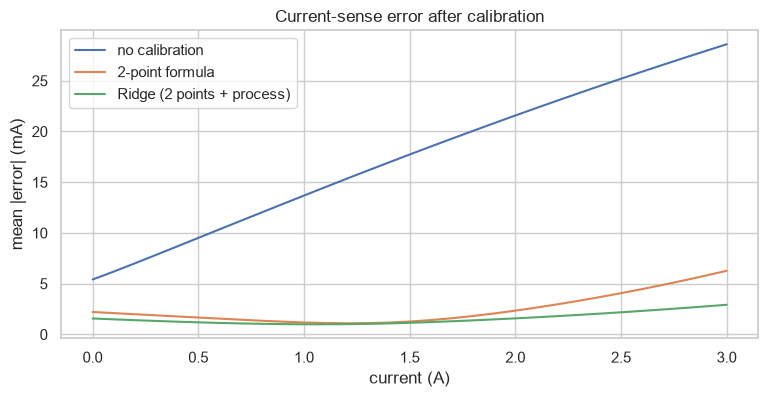

In [17]:
best_cs = cs_res.iloc[2:].sort_values("worst_error_mA").iloc[0].method
preds = [fitted[(c, best_cs)].predict(test[CS_FEATS]) for c in CS_T]
true = sensor_error(*(test[c].values for c in CS_T))
plt.figure(figsize=(9, 4))
plt.plot(I, np.abs(true).mean(0) * 1000, label="no calibration")
plt.plot(I, np.abs(true - sensor_error(*two_pt)).mean(0) * 1000, label="2-point formula")
plt.plot(I, np.abs(true - sensor_error(*preds)).mean(0) * 1000, label=f"{best_cs} (2 points + process)")
plt.xlabel("current (A)"); plt.ylabel("mean |error| (mA)"); plt.title("Current-sense error after calibration")
plt.legend(); plt.show()

# Part 7, Task D: latent defect screening
About 0.4% of dies carry a hidden defect that shows up later. Can sort-time measurements flag them?
- **Rule:** the datasheet limits, efficiency below 88% or load regulation above 10 mV.
- **Isolation Forest:** unsupervised anomaly detection on several measurements. It needs no defect labels, which matters because real labels are rare.

Metrics: **recall** (share of defects caught), **precision** (share of flagged dies that are really defective), and **% of dies flagged** (the cost of extra testing).

In [18]:
ANOM = ["efficiency_1A_pct", "load_reg_mV", "vref_untrim_V"] + [f"{r}_untrim_ratio" for r in RAILS] + ["cs_gain_2pt", "cs_off_2pt"]
allp = pd.concat([train, test, others], ignore_index=True)
y = allp.latent_defect.values

def report(name, flag, score=None):
    tp = (flag & y).sum()
    return {"method": name, "flagged_%": flag.mean() * 100, "recall_%": tp / y.sum() * 100,
            "precision_%": tp / max(flag.sum(), 1) * 100,
            "ROC_AUC": roc_auc_score(y, score) if score is not None else np.nan,
            "PR_AUC": average_precision_score(y, score) if score is not None else np.nan}

rule = (allp.efficiency_1A_pct < 88) | (allp.load_reg_mV > 10)
iso = IsolationForest(n_estimators=300, contamination=0.005, random_state=SEED).fit(StandardScaler().fit_transform(allp[ANOM]))
score = -iso.score_samples(StandardScaler().fit_transform(allp[ANOM]))
rows = [report("Rule: eff<88 or load_reg>10", rule.values)]
for pct in [0.5, 1.0]:
    rows.append(report(f"IsolationForest top {pct}%", score >= np.quantile(score, 1 - pct / 100), score))
print(f"Latent defects: {y.sum()} of {len(y)} dies ({y.mean():.2%})\n")
print(pd.DataFrame(rows).round(2).to_string(index=False))

Latent defects: 43 of 11060 dies (0.39%)

                     method  flagged_%  recall_%  precision_%  ROC_AUC  PR_AUC
Rule: eff<88 or load_reg>10       0.39    100.00       100.00      NaN     NaN
   IsolationForest top 0.5%       0.51     32.56        25.00     0.99    0.23
   IsolationForest top 1.0%       1.00     41.86        16.22     0.99    0.23


## 7.1 Picture: where the defects sit

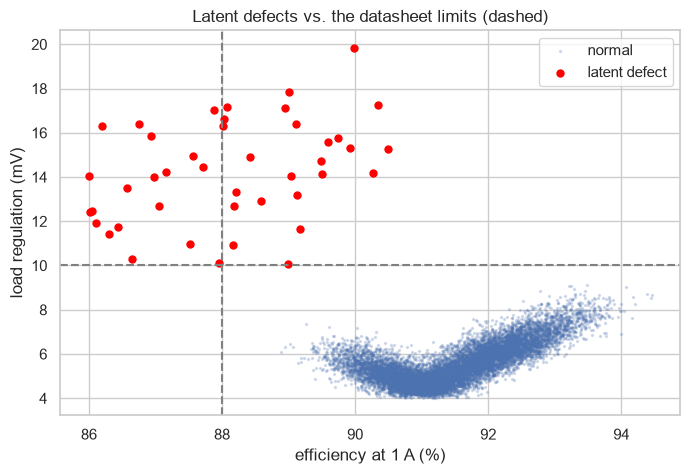

In [19]:
plt.figure(figsize=(8, 5))
plt.scatter(allp.efficiency_1A_pct, allp.load_reg_mV, s=2, alpha=0.2, label="normal")
plt.scatter(allp[y].efficiency_1A_pct, allp[y].load_reg_mV, s=25, color="red", label="latent defect")
plt.axvline(88, ls="--", color="grey"); plt.axhline(10, ls="--", color="grey")
plt.xlabel("efficiency at 1 A (%)"); plt.ylabel("load regulation (mV)"); plt.legend()
plt.title("Latent defects vs. the datasheet limits (dashed)"); plt.show()

# Part 8, Task E: transfer to PMIC-P2 and PMIC-C7
The best reference-only rail models, trained on P1 only, are used **as is** on P2 and C7. These derivatives have different rail voltages (for example, C7's ldo1 is 2.5 V instead of 1.8 V) and a different package.

In [20]:
rows = []
for r in RAILS:
    m = fitted[(r, best_s2[r].model)]
    for d in ["PMIC-P2", "PMIC-C7"]:
        part = others[others.derivative == d]
        e = evaluate(r, part, m.predict(part[REF_FEATS]), best_s2[r].model); e["derivative"] = d; rows.append(e)
tr = pd.DataFrame(rows)
print(tr[["trim", "derivative", "model", "exact_%", "within1_%", "AI_iters", "spec_pass_%"]].round(2).to_string(index=False))
print("\nP1 test within ±1 for comparison:", {r: round(best_s2[r]["within1_%"], 1) for r in RAILS})

 trim derivative model  exact_%  within1_%  AI_iters  spec_pass_%
buck1    PMIC-P2 Ridge    47.02      95.30      1.76       100.00
buck1    PMIC-C7 Ridge    44.67      91.68      1.97        99.82
buck2    PMIC-P2 Ridge    49.91      95.84      1.71       100.00
buck2    PMIC-C7 Ridge    50.36      95.03      1.75        99.91
 ldo1    PMIC-P2 Ridge    48.52      93.79      1.83        99.76
 ldo1    PMIC-C7 Ridge    47.11      92.41      1.91       100.00
 ldo2    PMIC-P2 Ridge    45.69      93.19      1.88        99.82
 ldo2    PMIC-C7 Ridge    45.21      91.50      1.97        99.37

P1 test within ±1 for comparison: {'buck1': np.float64(93.8), 'buck2': np.float64(95.5), 'ldo1': np.float64(95.0), 'ldo2': np.float64(92.6)}


# Part 9, Task F: customer OTP request checker
A wrong OTP default can damage the customer's processor, so every request is checked before an OTP image is made.

## 9.1 Rule-based checker
The rules come from the datasheet, checked in priority order:
1. any rail voltage outside its limits → `out_of_range`
2. I²C address reserved (0x00 to 0x07 or 0x78 to 0x7F) → `address_reserved`
3. address already used on the customer's bus → `address_collision`
4. sequence missing or repeating a rail → `invalid_sequence`
5. ldo2 (3.3 V I/O) powered up first → `sequence_conflict`
6. otherwise → `valid`

In [21]:
def check_request(r):
    if any(not LIMITS[x][0] <= r[f"{x}_V"] <= LIMITS[x][1] for x in RAILS):
        return "out_of_range"
    if r.i2c_addr_int <= 0x07 or r.i2c_addr_int >= 0x78:
        return "address_reserved"
    if r.i2c_addr_int in r.bus_list:
        return "address_collision"
    seq = r.sequence.split(">")
    if sorted(seq) != sorted(RAILS):
        return "invalid_sequence"
    if seq[0] == "ldo2":
        return "sequence_conflict"
    return "valid"

req["rule_pred"] = req.apply(check_request, axis=1)
print(f"Rule checker accuracy: {accuracy_score(req.label, req.rule_pred):.1%}\n")
labels = sorted(req.label.unique())
print(pd.DataFrame(confusion_matrix(req.label, req.rule_pred, labels=labels), index=labels, columns=labels).to_string())

Rule checker accuracy: 100.0%

                   address_collision  address_reserved  invalid_sequence  out_of_range  sequence_conflict  valid
address_collision                 32                 0                 0             0                  0      0
address_reserved                   0                18                 0             0                  0      0
invalid_sequence                   0                 0                31             0                  0      0
out_of_range                       0                 0                 0            44                  0      0
sequence_conflict                  0                 0                 0             0                 35      0
valid                              0                 0                 0             0                  0    240


## 9.2 Could ML do it instead?
A Decision Tree and a Random Forest trained on the raw request fields (voltages, address number, bus size, rail positions), scored with 5-fold stratified cross-validation. ML has to **learn** the rules from only 400 examples.

In [22]:
RAW = [f"{r}_V" for r in RAILS] + ["i2c_addr_int", "n_bus_devices"] + [f"seq_pos_{r}" for r in RAILS]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = [{"method": "Rule checker", "accuracy_%": accuracy_score(req.label, req.rule_pred) * 100}]
for name, clf in [("Decision Tree", DecisionTreeClassifier(random_state=SEED)),
                  ("Random Forest", RandomForestClassifier(n_estimators=300, random_state=SEED))]:
    p = cross_val_predict(clf, req[RAW], req.label, cv=cv)
    rows.append({"method": f"{name} (raw fields)", "accuracy_%": accuracy_score(req.label, p) * 100})
    if name == "Random Forest":
        rf_pred = p
print(pd.DataFrame(rows).round(1).to_string(index=False))
print("\nRandom Forest per class:\n", classification_report(req.label, rf_pred, zero_division=0))

                    method  accuracy_%
              Rule checker       100.0
Decision Tree (raw fields)        98.5
Random Forest (raw fields)        96.2

Random Forest per class:
                    precision    recall  f1-score   support

address_collision       1.00      1.00      1.00        32
 address_reserved       1.00      0.89      0.94        18
 invalid_sequence       1.00      0.84      0.91        31
     out_of_range       1.00      0.82      0.90        44
sequence_conflict       0.88      1.00      0.93        35
            valid       0.96      1.00      0.98       240

         accuracy                           0.96       400
        macro avg       0.97      0.92      0.94       400
     weighted avg       0.97      0.96      0.96       400



**Why the rules win here:** the rules are exact, explainable and auditable. For example, an address collision depends on whether the address is *in a list*, which a tree cannot see from numeric columns. For a safety-critical OTP image, **use the rule checker**; ML adds risk without benefit.

# Part 10: Can task A be optimized further?

## 10.1 Feature engineering
Physics says each rail's untrimmed output scales with the trimmed reference. So the code the rail would need from the reference alone is:

`ref_ideal_code = 32 + (0.600 / vref_trimmed − 1) / 0.002`

We add it (and the reference error in mV) and retrain every model.

In [23]:
for d in (train, test, others):
    d["ref_ideal_code"] = 32 + (0.600 / d.vref_trimmed_sort_V - 1) / 0.002
    d["vref_err_mV"] = (d.vref_untrim_V - 0.600) * 1000
FE_FEATS = REF_FEATS + ["ref_ideal_code", "vref_err_mV"]
res_fe = []
for r in RAILS:
    for name, m in make_models().items():
        m.fit(train[FE_FEATS], train[CFG[r]["label"]])
        res_fe.append(evaluate(r, test, m.predict(test[FE_FEATS]), name + " +FE")); fitted[(r, name + " +FE")] = m
res_fe = pd.DataFrame(res_fe)
both = res_s2.assign(model=res_s2.model + " +FE").merge(res_fe, on=["trim", "model"], suffixes=("_base", "_FE"))
print(both[["trim", "model", "within1_%_base", "within1_%_FE", "exact_%_base", "exact_%_FE"]].round(2).to_string(index=False))

 trim            model  within1_%_base  within1_%_FE  exact_%_base  exact_%_FE
buck1        Ridge +FE           93.76         93.76         46.29       46.29
buck1 RandomForest +FE           83.05         83.09         36.71       36.84
buck1      XGBoost +FE           90.91         91.09         43.85       45.43
buck1     LightGBM +FE           90.14         90.37         43.35       43.13
buck1          MLP +FE           89.74         91.68         40.28       41.77
buck2        Ridge +FE           95.52         95.52         48.15       48.15
buck2 RandomForest +FE           86.93         86.66         38.74       38.56
buck2      XGBoost +FE           92.81         92.68         44.39       44.53
buck2     LightGBM +FE           91.41         91.32         43.22       42.63
buck2          MLP +FE           90.46         92.90         40.87       44.85
 ldo1        Ridge +FE           94.98         94.98         47.65       47.65
 ldo1 RandomForest +FE           89.01         89.06

## 10.2 Hyperparameter tuning
The top two models per rail (after feature engineering) are tuned with RandomizedSearchCV and 4-fold **GroupKFold by wafer**.

In [24]:
GRIDS = {
    "Ridge": {"ridge__alpha": np.logspace(-3, 2, 20)},
    "RandomForest": {"n_estimators": [200, 400, 600], "max_depth": [None, 12, 20], "min_samples_leaf": [1, 2, 4, 8],
                     "max_features": [0.5, 0.7, 1.0]},
    "XGBoost": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 5, 6],
                "subsample": [0.7, 0.85, 1.0], "colsample_bytree": [0.6, 0.8, 1.0], "min_child_weight": [1, 3, 5]},
    "LightGBM": {"n_estimators": [300, 600, 900], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [15, 31, 63],
                 "min_child_samples": [10, 20, 40], "subsample": [0.7, 0.85, 1.0], "subsample_freq": [1],
                 "colsample_bytree": [0.6, 0.8, 1.0]},
    "MLP": {"mlpregressor__hidden_layer_sizes": [(64, 32), (128, 64), (128, 64, 32)],
            "mlpregressor__alpha": [1e-4, 1e-3, 1e-2], "mlpregressor__learning_rate_init": [1e-3, 3e-3]},
}
res_tuned = []
for r in RAILS:
    for name in rank(res_fe[res_fe.trim == r]).model.head(2).str.replace(" +FE", "", regex=False):
        s = RandomizedSearchCV(make_models()[name], GRIDS[name], n_iter=12, cv=GroupKFold(n_splits=4),
                               scoring="neg_mean_absolute_error", random_state=SEED, n_jobs=-1)
        s.fit(train[FE_FEATS], train[CFG[r]["label"]], groups=train.wafer_id)
        e = evaluate(r, test, s.best_estimator_.predict(test[FE_FEATS]), name + " +FE +tuned")
        res_tuned.append(e); fitted[(r, name + " +FE +tuned")] = s.best_estimator_
        print(f"{r:6s} {name:12s} cv MAE {-s.best_score_:.3f} | test ±1 {e['within1_%']:.2f}% | exact {e['exact_%']:.2f}%")
res_tuned = pd.DataFrame(res_tuned)

buck1  Ridge        cv MAE 0.653 | test ±1 93.76% | exact 46.38%


buck1  MLP          cv MAE 0.773 | test ±1 91.64% | exact 42.13%


buck2  Ridge        cv MAE 0.607 | test ±1 95.57% | exact 48.15%


buck2  MLP          cv MAE 0.714 | test ±1 91.68% | exact 43.72%


ldo1   Ridge        cv MAE 0.666 | test ±1 94.98% | exact 47.65%


ldo1   XGBoost      cv MAE 0.738 | test ±1 93.63% | exact 48.24%


ldo2   Ridge        cv MAE 0.673 | test ±1 92.63% | exact 45.12%


ldo2   MLP          cv MAE 0.792 | test ±1 90.78% | exact 43.17%


## 10.3 Before vs. after optimization (reference-only rail codes)

In [25]:
allA = pd.concat([res_s2, res_fe, res_tuned], ignore_index=True)
show = ["model", "MAE", "exact_%", "within1_%", "within2_%", "AI_iters", "iters_saved_%", "spec_pass_%"]
for r in RAILS:
    a = allA[allA.trim == r]
    pick = pd.concat([a[a.model == best_s2[r].model], rank(a[a.model.str.endswith("+FE")]).head(1),
                      a[a.model.str.endswith("+tuned")]])
    print(f"\n===== {r} =====\n" + pick[show].round(3).to_string(index=False))


===== buck1 =====
           model   MAE  exact_%  within1_%  within2_%  AI_iters  iters_saved_%  spec_pass_%
           Ridge 0.644   46.293     93.761     99.910     1.849         70.790       99.864
       Ridge +FE 0.644   46.293     93.761     99.910     1.849         70.790       99.864
Ridge +FE +tuned 0.644   46.383     93.761     99.910     1.848         70.804       99.864
  MLP +FE +tuned 0.697   42.134     91.637     99.729     1.997         68.454       99.684

===== buck2 =====
           model   MAE  exact_%  within1_%  within2_%  AI_iters  iters_saved_%  spec_pass_%
           Ridge 0.614   48.146     95.524     99.955     1.742         72.475       99.955
       Ridge +FE 0.614   48.146     95.524     99.955     1.742         72.475       99.955
Ridge +FE +tuned 0.614   48.146     95.570     99.955     1.740         72.511       99.955
  MLP +FE +tuned 0.696   43.716     91.682     99.231     1.979         68.740       99.231

===== ldo1 =====
             model   MAE

# Part 11: Final selection, test-time saving and saving the models

## 11.1 Final model per trim
Ranking rule: ±1 code %, then exact %, then MAE.
- **Rails:** the best reference-only model across all versions.
- **vref and thresholds:** the simple formula is kept **unless ML is clearly better** (more than 0.5 points higher in exact or ±1 %). A model that is only as good as a formula is not worth deploying.

In [26]:
FINAL = {r: rank(allA[allA.trim == r]).iloc[0].model for r in RAILS}
def pick_threshold(t):
    b = res_b[res_b.trim == t]
    f, best = b[b.model.str.startswith("Formula")].iloc[0], rank(b).iloc[0]
    clearly_better = (best["exact_%"] - f["exact_%"] > 0.5) or (best["within1_%"] - f["within1_%"] > 0.5)
    return best if clearly_better else f

FINAL.update({t: pick_threshold(t).model for t in ["vref", "ovp", "uvlo", "ilim"]})
final_rows = pd.concat([rank(allA[allA.trim == r]).head(1) for r in RAILS] +
                       [pick_threshold(t).to_frame().T for t in ["vref", "ovp", "uvlo", "ilim"]]).infer_objects()
print(final_rows[["trim", "model", "exact_%", "within1_%", "AI_iters", "conv_iters"]].round(2).to_string(index=False))

 trim                   model  exact_%  within1_%  AI_iters  conv_iters
buck1        Ridge +FE +tuned    46.38      93.76      1.85        6.33
buck2        Ridge +FE +tuned    48.15      95.57      1.74        6.33
 ldo1               Ridge +FE    47.65      94.98      1.77        6.33
 ldo2               Ridge +FE    45.12      92.63      1.92        6.33
 vref RandomForest (measured)    79.57      99.73      1.22        6.33
  ovp      Formula (measured)    99.91     100.00      1.00        4.00
 uvlo      Formula (measured)    99.91     100.00      1.00        4.00
 ilim      Formula (measured)    99.86     100.00      1.00        5.00


## 11.2 Test-time saving per die
Adds up the AI iterations of all 8 trims and compares them with today's full binary search.

In [27]:
ai_total = final_rows.AI_iters.sum()
print(f"Iterations per die : today {CONV_ITERS:.1f} -> AI {ai_total:.1f}")
print(f"Trim time per die  : today {CONV_ITERS * MS_PER_ITER:.1f} ms -> AI {ai_total * MS_PER_ITER:.1f} ms "
      f"({100 * (1 - ai_total / CONV_ITERS):.0f}% less)")
print("Rail measurements skipped: 4 per die (reference-only prediction)")

Iterations per die : today 44.7 -> AI 11.5
Trim time per die  : today 35.7 ms -> AI 9.2 ms (74% less)
Rail measurements skipped: 4 per die (reference-only prediction)


## 11.3 Save the final models
Saved compressed. The Streamlit app will load this file later.

In [28]:
bundle = {"rails": {r: {"model": fitted[(r, FINAL[r])], "name": FINAL[r],
                        "features": FE_FEATS if "+FE" in FINAL[r] else REF_FEATS, "config": CFG[r]} for r in RAILS},
          "thresholds": {t: {"model": fitted[(t, FINAL[t])][0], "features": fitted[(t, FINAL[t])][1], "name": FINAL[t],
                             "config": CFG[t]} for t in ["vref", "ovp", "uvlo", "ilim"] if FINAL[t] in
                         [k[1] for k in fitted if k[0] == t]},
          "current_sense": {c: fitted[(c, best_cs)] for c in CS_T}, "cs_features": CS_FEATS,
          "otp_checker_limits": LIMITS}
joblib.dump(bundle, "pmic_models.joblib", compress=3)
print("Saved pmic_models.joblib:", round(os.path.getsize("pmic_models.joblib") / 1e6, 1), "MB")
print("Formula used (no model needed) for:", [t for t in ["vref", "ovp", "uvlo", "ilim"] if t not in bundle["thresholds"]])

Saved pmic_models.joblib: 6.3 MB
Formula used (no model needed) for: ['ovp', 'uvlo', 'ilim']


## 11.4 Use the saved models on one die

In [29]:
saved = joblib.load("pmic_models.joblib")
die = test.iloc[[0]]
print("Die:", die.die_id.iloc[0], "| derivative:", die.derivative.iloc[0])
for r, b in saved["rails"].items():
    p = int(to_code(b["model"].predict(die[b["features"]]), r)[0])
    print(f"  {r:6s} predicted code {p:2d} | true {die[CFG[r]['label']].iloc[0]:2d} | apply + verify")

Die: PMIC-000000 | derivative: PMIC-P1
  buck1  predicted code 30 | true 31 | apply + verify
  buck2  predicted code 32 | true 32 | apply + verify
  ldo1   predicted code 33 | true 33 | apply + verify
  ldo2   predicted code 33 | true 33 | apply + verify


# Part 12: Would deep learning, GANs or reinforcement learning help here?

- **Deep learning (MLP):** tested in every comparison. It never won. For the rail codes, **Ridge (a linear model) beat every other model**, because the physics is close to linear: each rail output scales with the trimmed reference, and process shifts are small, near-linear effects. A neural network adds complexity without adding accuracy.
- **Multi-output modelling:** tested in 4.3. One model for all 4 rails was *worse* than separate models, because each rail responds to process in its own way. The coupling is already captured by giving every rail model the same reference features.
- **GAN:** would generate fake dies for the small derivatives. Not needed: the P1 models already transfer to P2 and C7 with about 92–96% within ±1 code. Synthetic training data can't be trusted for OTP programming anyway.
- **RNN / LSTM:** there is no sequence in the data (one row per die), so they don't apply.
- **Reinforcement learning:** could learn the best *order* of trims. But predict-then-verify already brings the PMIC from 44.7 to about 11.5 iterations per die, and RL would need a live tester or simulator to train and would be hard to certify.
- **Anomaly detection:** Isolation Forest (unsupervised ML) was *worse* than the simple datasheet rule, which caught all 43 latent defects while flagging only 0.39% of dies. In this data the defects push efficiency and load regulation past the datasheet limits.

**Conclusion:** use the simplest method that works. That means linear regression for the rails, a formula for the thresholds, ML for the current-sense calibration, and rules for the OTP requests and defect screening.

# Part 13: Summary: what was chosen and why

| Task | Chosen method | Result | Why |
|---|---|---|---|
| **A. Rail codes, reference only** | **Ridge regression** (+ physics feature, tuned) | 92.6–95.6% within ±1 code, spec pass ≥ 99.7%, **no rail measurements** | Most accurate of 6 models; the relationship is near-linear; tiny, fast and fully explainable |
| B. Reference trim | Random Forest on the untrimmed reading | 79.6% exact vs. 60.0% for the formula | Learns each die's trim-DAC gain error from process data |
| B. OVP / UVLO / current limit | Formula with one measurement | ~100% exact | Already perfect, so ML adds nothing. Predicting *without* measuring was too weak (54–82% within ±1) |
| C. Current sense | Ridge from 2 points + process data | Worst-case error 28.9 → 3.3 mA (2-point formula: 6.6 mA) | Recovers the non-linearity that 2 points alone cannot, so the full sweep is skipped |
| D. Latent defects | Datasheet rule | 100% recall, 100% precision | Simple, exact and auditable; Isolation Forest was worse |
| E. Derivatives P2, C7 | Same P1 rail models, no retraining | 91.5–95.8% within ±1 | One base model serves the family (the brief's transfer idea) |
| F. Customer OTP requests | Rule checker | 100% accuracy (ML: 96–98.5%) | Safety-critical: rules are exact and auditable |

**Business result:** trim iterations per die drop from **44.7 to about 11.5**, and trim time from **35.7 ms to about 9.2 ms (74% less)**. Four rail measurements are skipped per die, and the current sensor needs 2 points instead of a full sweep.

**Honest notes:**
- Feature engineering and tuning gave almost no gain: Ridge already captures the physics.
- Reference-only prediction is less exact than measuring each rail (about 47% vs. 85% exact). The verify step catches the misses (one extra measurement for ±1), and fewer than 1 in 10 dies fall back to the full search.
- This is synthetic data. Validate on real PMIC test data before any OTP is programmed from a prediction.

## Project summary prompt (copy and paste)
```text
Notebook 02 (PMIC) of my AI-Optimized Trim & Fuse project. Data: pmic_trim_otp.csv (11,060 dies,
derivatives PMIC-P1 / P2 / C7) and pmic_otp_config_requests.csv (400 customer requests).
Split by wafer, trained on P1, tested on held-out P1 wafers and on P2/C7 without retraining.

Main task: predict all 4 rail trim codes (buck1, buck2, ldo1, ldo2) from the reference
measurement + process data only, skipping 4 rail measurements. Compared Ridge, Random Forest,
XGBoost, LightGBM and MLP, single- vs. multi-output, plus feature engineering and GroupKFold
tuning. Ridge won (92.6-95.6% within +/-1 code, spec pass >= 99.7%), because the rails scale
almost linearly with the trimmed reference. Other tasks: reference trim (RF, 79.6% exact vs
60.0% formula), thresholds (formula is already ~100%), current-sense calibration from 2 points
(Ridge, worst error 28.9 -> 3.3 mA), latent-defect screening (datasheet rule 100% recall,
better than Isolation Forest), OTP request checking (rules 100%, ML 96-98.5%).
Result: 44.7 -> 11.5 trim iterations per die, 35.7 -> 9.2 ms (-74%).
Lesson: use the simplest method that works; ML only where it clearly beats physics or rules.
```